In [1]:
import pandas as pd
import numpy as np

admissions = pd.read_csv("admissions.csv")
patients = pd.read_csv("Patients.csv")  
icustays = pd.read_csv("icustays.csv")

print(admissions.head())
print(patients.head())
print(icustays.head())

   subject_id   hadm_id            admittime            dischtime deathtime  \
0    10000032  22595853  2180-05-06 22:23:00  2180-05-07 17:15:00       NaN   
1    10000032  22841357  2180-06-26 18:27:00  2180-06-27 18:49:00       NaN   
2    10000032  25742920  2180-08-05 23:44:00  2180-08-07 17:50:00       NaN   
3    10000032  29079034  2180-07-23 12:35:00  2180-07-25 17:55:00       NaN   
4    10000068  25022803  2160-03-03 23:16:00  2160-03-04 06:26:00       NaN   

   admission_type admit_provider_id      admission_location  \
0          URGENT            P49AFC  TRANSFER FROM HOSPITAL   
1        EW EMER.            P784FA          EMERGENCY ROOM   
2        EW EMER.            P19UTS          EMERGENCY ROOM   
3        EW EMER.            P06OTX          EMERGENCY ROOM   
4  EU OBSERVATION            P39NWO          EMERGENCY ROOM   

  discharge_location insurance language marital_status   race  \
0               HOME  Medicaid  English        WIDOWED  WHITE   
1               

In [3]:
print(admissions.columns)
print(patients.columns)
print(icustays.columns)

Index(['subject_id', 'hadm_id', 'admittime', 'dischtime', 'deathtime',
       'admission_type', 'admit_provider_id', 'admission_location',
       'discharge_location', 'insurance', 'language', 'marital_status', 'race',
       'edregtime', 'edouttime', 'hospital_expire_flag'],
      dtype='object')
Index(['subject_id', 'gender', 'anchor_age', 'anchor_year',
       'anchor_year_group', 'dod'],
      dtype='object')
Index(['subject_id', 'hadm_id', 'stay_id', 'first_careunit', 'last_careunit',
       'intime', 'outtime', 'los'],
      dtype='object')


In [5]:
preview = pd.read_csv("labevents.csv", nrows=100)
print(preview)

print(preview.columns)

    labevent_id  subject_id  hadm_id  specimen_id  itemid order_provider_id  \
0             1    10000032      NaN      2704548   50931            P69FQC   
1             2    10000032      NaN     36092842   51071            P69FQC   
2             3    10000032      NaN     36092842   51074            P69FQC   
3             4    10000032      NaN     36092842   51075            P69FQC   
4             5    10000032      NaN     36092842   51079            P69FQC   
..          ...         ...      ...          ...     ...               ...   
95           96    10000032      NaN     95700408   50861               NaN   
96           97    10000032      NaN     95700408   50862               NaN   
97           98    10000032      NaN     95700408   50863               NaN   
98           99    10000032      NaN     95700408   50868               NaN   
99          100    10000032      NaN     95700408   50878               NaN   

              charttime            storetime value 

In [7]:
admissions['admittime'] = pd.to_datetime(admissions['admittime'])
admissions['dischtime'] = pd.to_datetime(admissions['dischtime'])
icustays['intime'] = pd.to_datetime(icustays['intime'])
icustays['outtime'] = pd.to_datetime(icustays['outtime'])
admissions = admissions.sort_values(by=['subject_id', 'admittime'])

In [8]:
admissions['next_admit'] = admissions.groupby('subject_id')['admittime'].shift(-1)
admissions['readmitted_30d'] = (admissions['next_admit'] - admissions['dischtime']).dt.days <= 30
admissions['readmitted_30d'] = admissions['readmitted_30d'].fillna(False).astype(int)

In [9]:
merged = admissions.merge(patients, on="subject_id", how="left")
merged = merged.merge(icustays, on="hadm_id", how="left")

if 'subject_id' not in merged.columns:
    merged['subject_id'] = admissions['subject_id']

merged['icu_los'] = (merged['outtime'] - merged['intime']).dt.total_seconds() / 86400
merged['age'] = merged['anchor_age']
merged['gender'] = merged['gender'].map({'M': 1, 'F': 0})  
merged['hospital_expire_flag'] = merged['hospital_expire_flag']

merged['icu_los'] = merged['icu_los'].fillna(-1)
merged['age'] = merged['age'].fillna(-1)
merged['gender'] = merged['gender'].fillna(-1)
merged['hospital_expire_flag'] = merged['hospital_expire_flag'].fillna(-1)

In [10]:
# Final feature set for modeling 
model_input = merged[['subject_id', 'hadm_id', 'stay_id', 'age', 'gender', 'icu_los', 'hospital_expire_flag', 'readmitted_30d']]

# Saving final dataset
model_input.to_parquet('mimic4_cleaned.parquet')
model_input.to_csv('mimic4_cleaned.csv.gz', index=False, compression='gzip')

print("Preprocessing complete. Files saved: 'mimic4_cleaned.parquet' and 'mimic4_cleaned.csv.gz'")

d_labitems = pd.read_csv("d_labitems.csv")
print(d_labitems.head)
itemid_to_name = dict(zip(d_labitems['itemid'], d_labitems['label']))

Preprocessing complete. Files saved: 'mimic4_cleaned.parquet' and 'mimic4_cleaned.csv.gz'
<bound method NDFrame.head of       itemid                                label  fluid   category
0      50801           Alveolar-arterial Gradient  Blood  Blood Gas
1      50802                          Base Excess  Blood  Blood Gas
2      50803  Calculated Bicarbonate, Whole Blood  Blood  Blood Gas
3      50804                 Calculated Total CO2  Blood  Blood Gas
4      50805                    Carboxyhemoglobin  Blood  Blood Gas
...      ...                                  ...    ...        ...
1645   53186                                  MCH  Blood  Chemistry
1646   53187                                  PAN  Stool  Chemistry
1647   53188                          Lymphocytes  Blood  Chemistry
1648   53189                       Platelet Count  Blood  Chemistry
1649   53190                                 MXD%  Blood  Chemistry

[1650 rows x 4 columns]>


In [12]:
import glob


file_list = glob.glob("labevents_filtered_part_*.csv") 
labevents_filtered = pd.concat([pd.read_csv(file) for file in file_list], ignore_index=True)

print(f"Total lab rows after merging: {len(labevents_filtered)}")

agg = labevents_filtered.groupby(['hadm_id', 'itemid'])['valuenum'].agg(['mean', 'min', 'max', 'first']).reset_index()
agg.columns = ['hadm_id', 'itemid', 'mean', 'min', 'max', 'first']

C:\Users\syede\AppData\Local\Temp\ipykernel_14472\326790943.py:5: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  labevents_filtered = pd.concat([pd.read_csv(file) for file in file_list], ignore_index=True)
C:\Users\syede\AppData\Local\Temp\ipykernel_14472\326790943.py:5: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  labevents_filtered = pd.concat([pd.read_csv(file) for file in file_list], ignore_index=True)
C:\Users\syede\AppData\Local\Temp\ipykernel_14472\326790943.py:5: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  labevents_filtered = pd.concat([pd.read_csv(file) for file in file_list], ignore_index=True)
C:\Users\syede\AppData\Local\Temp\ipykernel_14472\326790943.py:5: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  labevents_filtered = pd.concat([pd.read_csv(file)

Total lab rows after merging: 21234338


In [14]:
melted = agg.melt(id_vars=['hadm_id', 'itemid'], var_name='stat', value_name='value')
melted['label'] = melted['itemid'].map(itemid_to_name)
melted['feature_name'] = melted['label'] + "_" + melted['stat']
melted = melted.groupby(['hadm_id', 'feature_name'])['value'].mean().reset_index()
pivoted = melted.pivot(index='hadm_id', columns='feature_name', values='value').reset_index()

In [15]:
cohort = pd.read_csv("mimic4_cleaned.csv.gz")

final = cohort.merge(pivoted, on='hadm_id', how='left')
final.to_csv("model_input_with_labs_named.csv.gz", index=False, compression='gzip')
print("Final dataset saved as model_input_with_labs_named.csv.gz")

Final dataset saved as model_input_with_labs_named.csv.gz


In [17]:
pd.read_csv("model_input_with_labs_named.csv.gz")

,subject_id,hadm_id,stay_id,age,gender,icu_los,hospital_expire_flag,readmitted_30d,Albumin_first,Albumin_max,...,Hematocrit_mean,Hematocrit_min,Lactate_first,Lactate_max,Lactate_mean,Lactate_min,Platelet Count_first,Platelet Count_max,Platelet Count_mean,Platelet Count_min
0,10000032.0,22595853,NaN,52,0,-1.000000,0,0,NaN,NaN,...,37.60,37.6,NaN,NaN,NaN,NaN,71.0,71.0,71.000000,71.0
1,10000032.0,22841357,NaN,52,0,-1.000000,0,1,2.7,2.7,...,35.50,35.5,NaN,NaN,NaN,NaN,137.0,137.0,137.000000,137.0
2,10000032.0,29079034,39553978.0,52,0,0.410266,0,1,3.8,3.8,...,33.45,32.1,NaN,NaN,NaN,NaN,94.0,95.0,94.500000,94.0
3,10000032.0,25742920,NaN,52,0,-1.000000,0,0,3.5,3.5,...,34.05,33.5,NaN,NaN,NaN,NaN,133.0,133.0,120.000000,107.0
4,10000068.0,25022803,NaN,19,0,-1.000000,0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
555239,NaN,29734428,NaN,46,0,-1.000000,0,0,3.2,3.2,...,32.70,28.7,1.9,1.9,1.90,1.9,507.0,507.0,369.736842,252.0
555240,NaN,25744818,36075953.0,46,0,1.790995,0,0,2.8,2.8,...,30.67,28.3,1.5,1.5,1.50,1.5,368.0,440.0,391.300000,324.0
555241,NaN,26071774,NaN,58,1,-1.000000,0,0,NaN,NaN,...,39.35,38.6,NaN,NaN,NaN,NaN,208.0,216.0,208.000000,198.0
555242,NaN,21033226,38978960.0,58,1,5.297766,1,0,4.3,4.3,...,36.60,33.0,0.9,7.0,3.66,0.9,272.0,321.0,277.333333,236.0


In [ ]:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score
import shap
import matplotlib.pyplot as plt

df = pd.read_csv("model_input_with_labs_named.csv.gz")
df_model = df.drop(columns=["subject_id", "hadm_id", "stay_id"], errors='ignore')
X = df_model.drop("readmitted_30d", axis=1)
y = df_model["readmitted_30d"]
X = X.fillna(-1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

ratio = y_train.value_counts()[0] / y_train.value_counts()[1]


model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    use_label_encoder=False,
    eval_metric="logloss",
    scale_pos_weight=ratio
)
model.fit(X_train, y_train)


y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("\n Classification Report:")
print(classification_report(y_test, y_pred))
print(" Accuracy:", accuracy_score(y_test, y_pred))
print(" AUC:", roc_auc_score(y_test, y_prob))

SHAP Summary Plot:


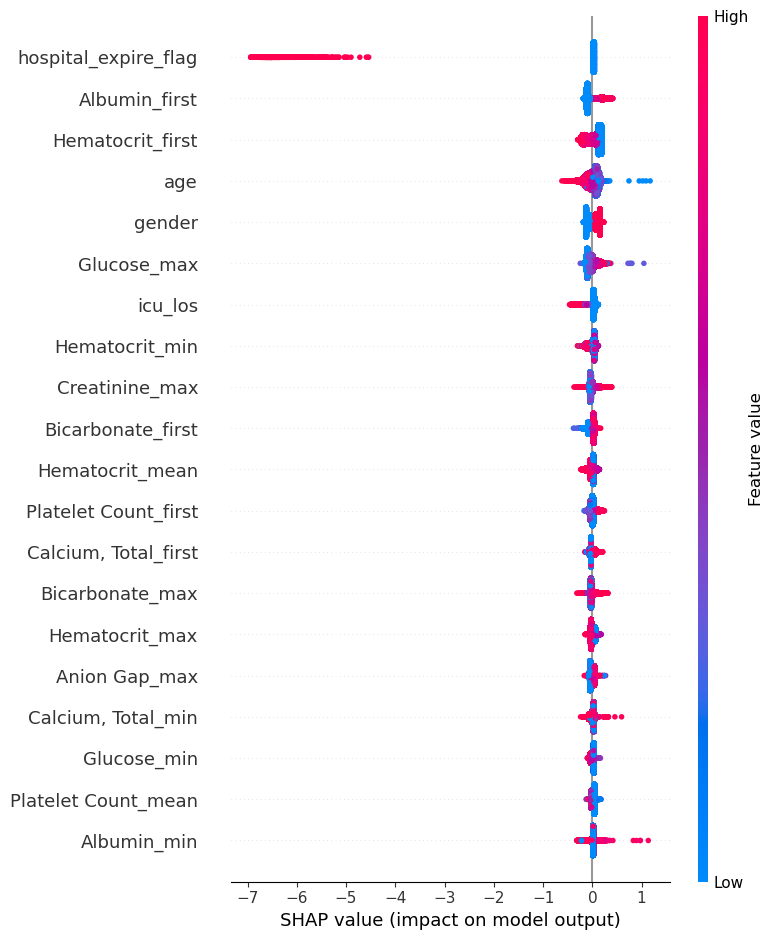

SHAP Feature Importance (bar):


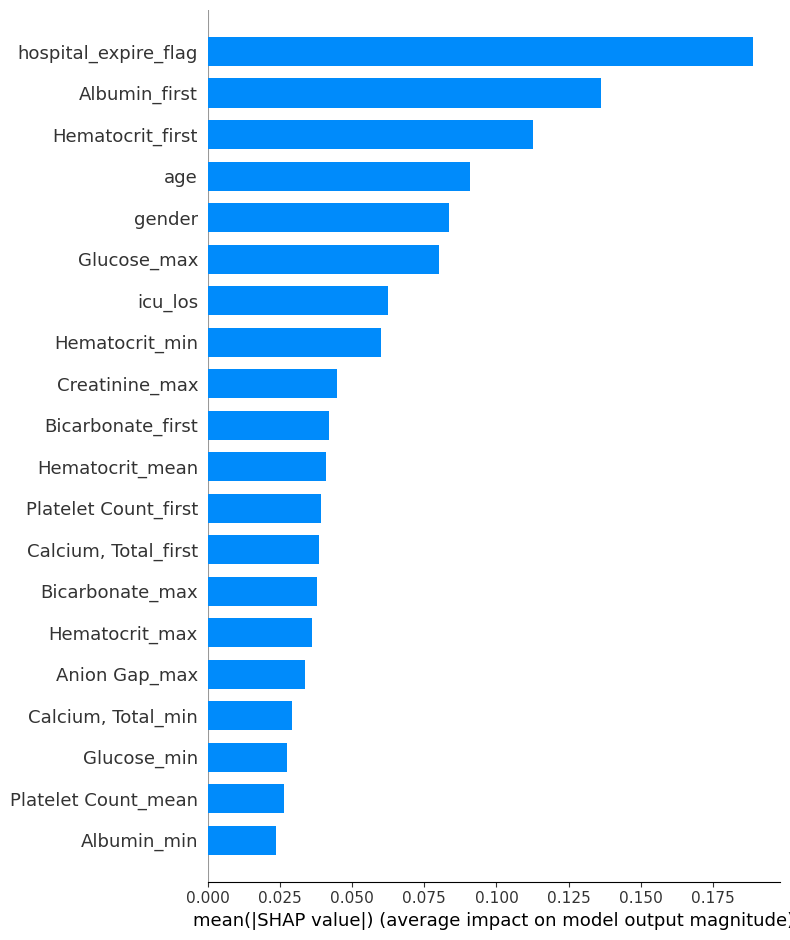

In [19]:
explainer = shap.Explainer(model)
shap_values = explainer(X_test)


print("SHAP Summary Plot:")
shap.summary_plot(shap_values, X_test)

print("SHAP Feature Importance (bar):")
shap.summary_plot(shap_values, X_test, plot_type="bar")

In [20]:
!pip install lime
lime_explainer = LimeTabularExplainer(X_train.values, feature_names=X_train.columns.tolist(), class_names=['No Readmit', 'Readmit'], mode='classification')
sample = X_test.iloc[0].values
exp = lime_explainer.explain_instance(sample, model.predict_proba, num_features=10)
exp.show_in_notebook(show_table=True, show_all=False)

NameError: name 'LimeTabularExplainer' is not defined

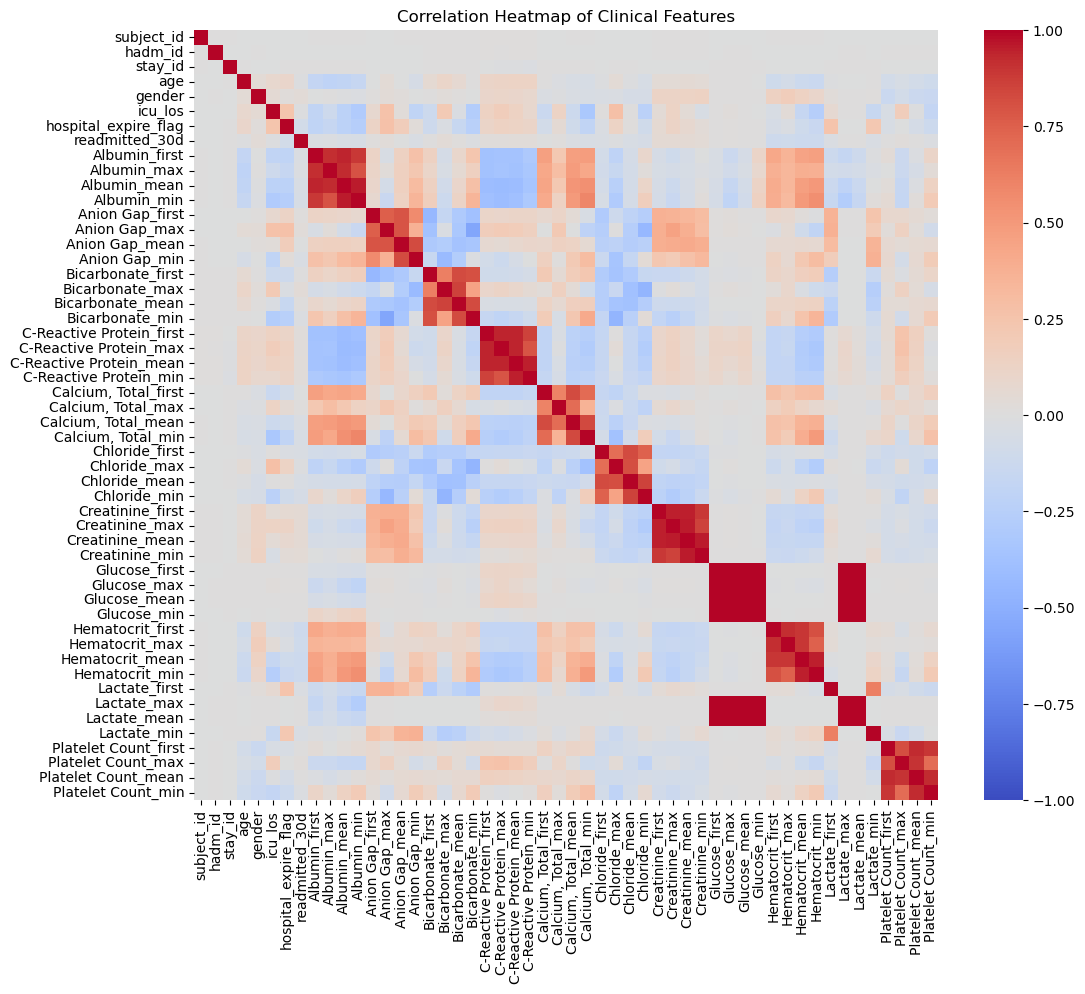

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt
corr = df.corr(numeric_only=True)
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap='coolwarm', vmax=1.0, vmin=-1.0, annot=False, fmt=".2f")
plt.title("Correlation Heatmap of Clinical Features")
plt.show()


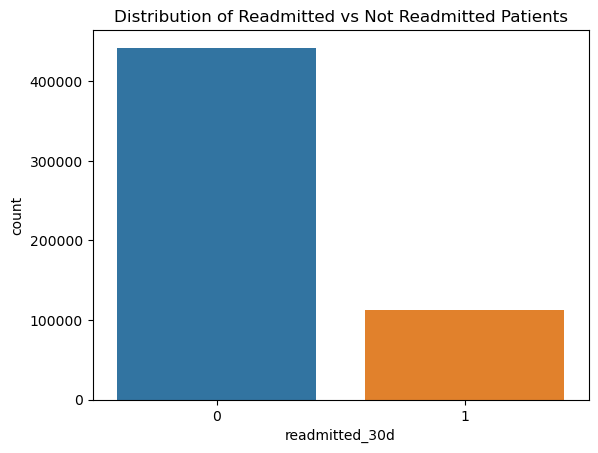

In [29]:
sns.countplot(data=df, x='readmitted_30d')
plt.title("Distribution of Readmitted vs Not Readmitted Patients")
plt.show()


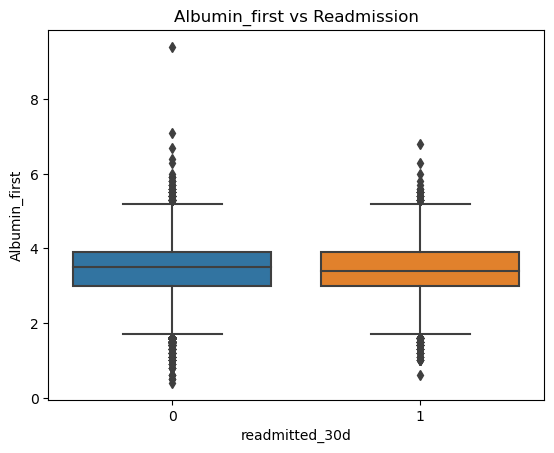

In [31]:
import seaborn as sns
sns.boxplot(data=df, x="readmitted_30d", y="Albumin_first")
plt.title("Albumin_first vs Readmission")
plt.show()


In [33]:
model= pd.read_csv("model_input_with_labs_named.csv.gz")
model.head(1000000)

,subject_id,hadm_id,stay_id,age,gender,icu_los,hospital_expire_flag,readmitted_30d,Albumin_first,Albumin_max,...,Hematocrit_mean,Hematocrit_min,Lactate_first,Lactate_max,Lactate_mean,Lactate_min,Platelet Count_first,Platelet Count_max,Platelet Count_mean,Platelet Count_min
0,10000032.0,22595853,NaN,52,0,-1.000000,0,0,NaN,NaN,...,37.60,37.6,NaN,NaN,NaN,NaN,71.0,71.0,71.000000,71.0
1,10000032.0,22841357,NaN,52,0,-1.000000,0,1,2.7,2.7,...,35.50,35.5,NaN,NaN,NaN,NaN,137.0,137.0,137.000000,137.0
2,10000032.0,29079034,39553978.0,52,0,0.410266,0,1,3.8,3.8,...,33.45,32.1,NaN,NaN,NaN,NaN,94.0,95.0,94.500000,94.0
3,10000032.0,25742920,NaN,52,0,-1.000000,0,0,3.5,3.5,...,34.05,33.5,NaN,NaN,NaN,NaN,133.0,133.0,120.000000,107.0
4,10000068.0,25022803,NaN,19,0,-1.000000,0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
555239,NaN,29734428,NaN,46,0,-1.000000,0,0,3.2,3.2,...,32.70,28.7,1.9,1.9,1.90,1.9,507.0,507.0,369.736842,252.0
555240,NaN,25744818,36075953.0,46,0,1.790995,0,0,2.8,2.8,...,30.67,28.3,1.5,1.5,1.50,1.5,368.0,440.0,391.300000,324.0
555241,NaN,26071774,NaN,58,1,-1.000000,0,0,NaN,NaN,...,39.35,38.6,NaN,NaN,NaN,NaN,208.0,216.0,208.000000,198.0
555242,NaN,21033226,38978960.0,58,1,5.297766,1,0,4.3,4.3,...,36.60,33.0,0.9,7.0,3.66,0.9,272.0,321.0,277.333333,236.0
